# What changes when volatility can move?

Price the same European call three ways. Black–Scholes gives a reference price. Heston lets the variance move with the market. Merton adds a different mechanism for extreme moves: a price jump. Follow each assumption from **price paths → return distribution → option prices → implied volatility**.

Work under a specified risk-neutral measure $Q$, in years, with continuous interest $r$ and zero dividends. Every model prices the same payoff, $C=e^{-rT}E^Q[(S_T-K)^+]$. The examples use hypothetical pricing parameters. In a market with unhedged volatility or jump risk, the physical dynamics alone do not determine the price.

## 1 · The benchmark

Black–Scholes assumes $dS/S=r\,dt+\sigma\,dW$. The terminal **log return** is normal with mean $(r-\sigma^2/2)T$ and variance $\sigma^2 T$; the stock price is lognormal. A single $\sigma$ prices every strike, so converting those prices back to Black–Scholes IV gives a horizontal line. The assumption we relax first is constant variance.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from src.models import bs_call, heston_call, merton_call, implied_volatility
from src.paths import heston_paths

spot, rate, T = 100., 0.02, 0.5
sigma = 0.20
h = dict(v0=sigma**2, theta=sigma**2, kappa=2., xi=0.5, rho=-0.7)
print(f"Six-month call at strike 100: ${bs_call(spot, 100., T, rate, sigma):.2f}")

Six-month call at strike 100: $6.12


## 2 · Heston: a second source of randomness

$$dS/S=r\,dt+\sqrt{v}\,dW_S,\qquad dv=\kappa(\theta-v)\,dt+\xi\sqrt{v}\,dW_v,\qquad dW_S\,dW_v=\rho\,dt.$$

Variance starts at $v_0$. The drift pulls it toward $\theta$ at speed $\kappa$; $\xi$ controls the size of its shocks. With $\rho<0$, a downward stock shock tends to coincide with an upward variance shock. A bad day can therefore change the distribution of the next day’s move. Both processes have continuous paths.

Follow the same color in the two panels. The lower panel plots **volatility** $\sqrt{v}$ so its units match the 20% benchmark. We simulate in log price and use full truncation for variance because an Euler step can overshoot zero. These parameters allow the continuous-time variance to reach zero.

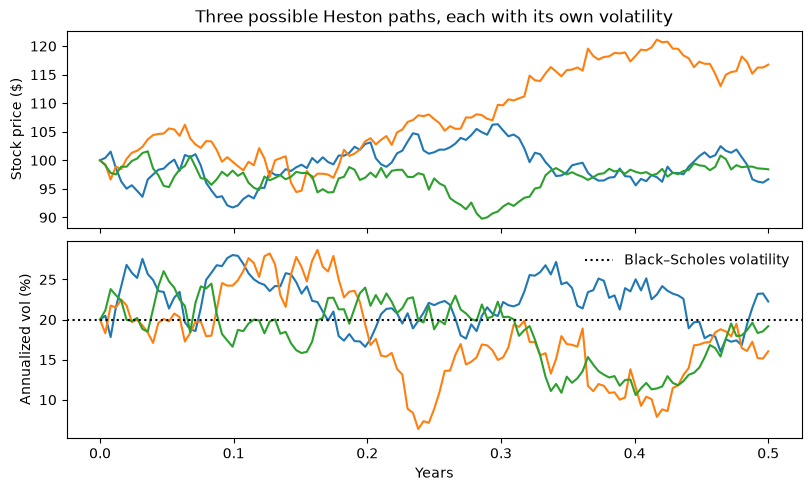

In [2]:
times, paths, vols, terminal = heston_paths(
    spot, T, rate, h["v0"], h["theta"], h["kappa"], h["xi"], h["rho"],
    n_paths=50_000, n_steps=126, n_sample=3, seed=42)
fig, axs = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True, layout="constrained")
axs[0].plot(times, paths)
axs[1].plot(times, 100 * vols)
axs[1].axhline(100 * sigma, ls=":", color="black", label="Black–Scholes volatility")
axs[0].set(ylabel="Stock price ($)", title="Three possible Heston paths, each with its own volatility")
axs[1].set(xlabel="Years", ylabel="Annualized vol (%)")
axs[1].legend(frameon=False)
plt.show()

### Where does non-normality appear?

At a very short time step the diffusion shock is Gaussian, conditional on the current variance. Across six months the amount of variance accumulated along a path is random, and the return and variance shocks are correlated. The resulting log return can be asymmetric with a heavier downside tail. Read the next chart at a fixed loss threshold: its height is the probability of finishing below that return.

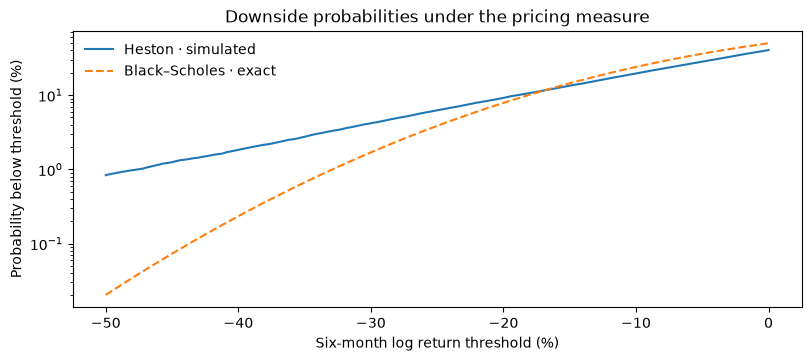

In [3]:
log_returns = np.sort(np.log(terminal / spot))
thresholds = np.linspace(-0.50, 0, 160)
heston_prob = np.searchsorted(log_returns, thresholds) / len(terminal)
bs_prob = norm.cdf(thresholds, loc=(rate - sigma**2 / 2) * T, scale=sigma * np.sqrt(T))
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.semilogy(100 * thresholds, 100 * heston_prob, label="Heston · simulated")
ax.semilogy(100 * thresholds, 100 * bs_prob, "--", label="Black–Scholes · exact")
ax.set(xlabel="Six-month log return threshold (%)", ylabel="Probability below threshold (%)",
       title="Downside probabilities under the pricing measure")
ax.legend(frameon=False)
plt.show()

## 3 · Merton: allow prices to jump

A diffusion can accumulate a large loss through many small moves. A jump model can cross the same distance in one instant. Draw a Poisson number $N_T$ of jumps with annual intensity $\lambda$. Each independent log jump $Y$ is normal with mean $\mu_J$ and standard deviation $\delta_J$. Conditional on $N_T=n$, the terminal log return is normal; averaging across possible counts gives a **mixture**.

$$\log(S_T/S_0)=(r-\lambda m-\sigma_d^2/2)T+\sigma_d W_T+\sum_{i=1}^{N_T}Y_i,\qquad m=E[e^Y-1].$$

Subtracting $\lambda m$ keeps the expected growth of the stock at the risk-free rate. For comparison, choose diffusion variance so that $\sigma_d^2+\lambda(\mu_J^2+\delta_J^2)=0.20^2$. This matches Black–Scholes annual log-return variance while allowing sudden losses. In Heston we match **expected integrated variance** via $v_0=\theta=0.20^2$.

In [4]:
intensity, jump_mean, jump_vol = 0.8, -0.12, 0.10
diffusion_vol = np.sqrt(sigma**2 - intensity * (jump_mean**2 + jump_vol**2))
jumps = dict(volatility=diffusion_vol, intensity=intensity, jump_mean=jump_mean, jump_vol=jump_vol)
print(f"Diffusion volatility {diffusion_vol:.1%}; chance of at least one jump in six months "
      f"{1 - np.exp(-intensity * T):.1%}")

Diffusion volatility 14.3%; chance of at least one jump in six months 33.0%


## 4 · Read model prices through implied volatility

Heston prices below use Fourier integration of its characteristic function (the expected complex exponential of the log return). Merton prices condition on jump count and sum the resulting call prices with Poisson weights. Invert each premium to obtain the constant Black–Scholes volatility that would reproduce it. This puts prices for cheap and expensive strikes on a common scale. The two panels vary expiry while holding model parameters fixed.

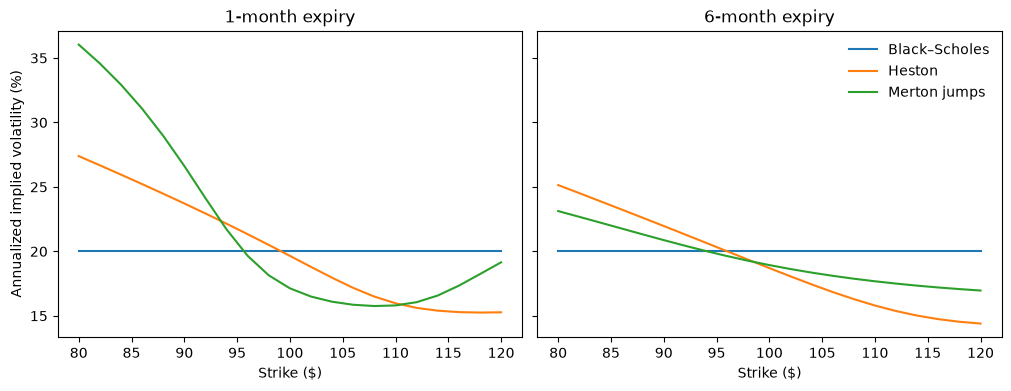

In [5]:
strikes = np.arange(80., 121., 2.)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, layout="constrained")
for ax, expiry in zip(axes, [1/12, T]):
    for label, prices in [
        ("Black–Scholes", bs_call(spot, strikes, expiry, rate, sigma)),
        ("Heston", heston_call(spot, strikes, expiry, rate, **h)),
        ("Merton jumps", merton_call(spot, strikes, expiry, rate, **jumps))]:
        iv = implied_volatility(prices, spot, strikes, expiry, rate)
        ax.plot(strikes, 100 * iv, label=label)
    ax.set(title=f"{expiry * 12:.0f}-month expiry", xlabel="Strike ($)")
axes[0].set_ylabel("Annualized implied volatility (%)")
axes[1].legend(frameon=False)
plt.show()

**What does the left wing cost in dollars?** With spot at 100, a one-month put struck at 90 pays only if the stock finishes more than 10% lower. Use European put–call parity to turn each call premium into the price of that protection. The jump model places substantial downside risk into a small number of short-horizon scenarios, so the put is more expensive even though Merton and Black–Scholes have identical log-return variance.

In [6]:
expiry, strike = 1/12, 90
call_prices = [bs_call(spot, strike, expiry, rate, sigma),
               heston_call(spot, strike, expiry, rate, **h),
               merton_call(spot, strike, expiry, rate, **jumps)]
put_prices = np.asarray(call_prices) - spot + strike * np.exp(-rate * expiry)
for model, price in zip(["Black–Scholes", "Heston", "Merton jumps"], put_prices):
    print(f"{model:<14} ${price:.3f} per share")

Black–Scholes  $0.068 per share
Heston         $0.164 per share
Merton jumps   $0.271 per share


### Isolate the Heston correlation effect

Keep the variance dynamics fixed and change only the correlation between the two shocks. Compare the left and right wings as correlation changes sign. Random variance alone can bend the curve, while correlation changes its tilt.

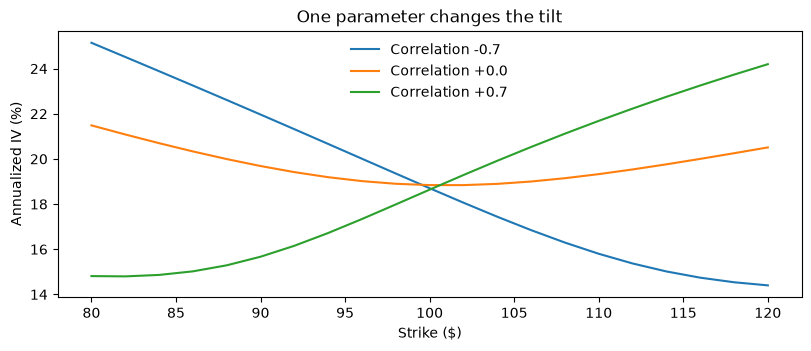

Heston ATM call, Fourier: $5.758
Heston ATM call, simulated: $5.788 (sampling standard error $0.031)


In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
for rho in [-0.7, 0., 0.7]:
    prices = heston_call(spot, strikes, T, rate, **(h | {"rho": rho}))
    ax.plot(strikes, 100 * implied_volatility(prices, spot, strikes, T, rate),
            label=f"Correlation {rho:+.1f}")
ax.set(xlabel="Strike ($)", ylabel="Annualized IV (%)", title="One parameter changes the tilt")
ax.legend(frameon=False)
plt.show()

payoffs = np.exp(-rate * T) * np.maximum(terminal - 100., 0)
print(f"Heston ATM call, Fourier: ${heston_call(spot, 100., T, rate, **h):.3f}")
print(f"Heston ATM call, simulated: ${payoffs.mean():.3f} "
      f"(sampling standard error ${payoffs.std(ddof=1)/np.sqrt(len(payoffs)):.3f})")

The simulation check has both sampling error and time-step bias. Fourier pricing avoids the Euler time step. Try setting Heston’s volatility of variance shocks to zero with initial and long-run variance equal, or turn off Merton’s jumps and restore diffusion volatility to 20%. Both limits give the Black–Scholes price.

A skew alone does not identify its cause. Heston explains how volatility can persist and move with returns, while its continuous stock paths omit overnight jumps. Merton captures abrupt repricing, while its constant jump intensity and diffusion volatility omit volatility clustering. The parameters here illustrate mechanisms and have not been fitted to market quotes.

**Original papers** · [Black and Scholes (1973)](https://doi.org/10.1086/260062) · [Heston (1993)](https://doi.org/10.1093/rfs/6.2.327) · [Merton (1976)](https://doi.org/10.1016/0304-405X(76)90022-2)